# Topology optimization of a waveguide bend: a 90° turn in a 3 µm square

**Question.** Two waveguides 0.55 µm wide, core index 2.25 in a cladding of index
1.444, meet at a right angle. In the 3 µm × 3 µm square where they meet, each point
may be core or cladding. Which pattern carries the most power at 1.55 µm from the
fundamental mode of one guide into the fundamental mode of the other?

We let gradients find it. The design is a pixel image of the square, and the chain
from pixels to the objective is differentiable end to end:

pixels ρ → **Helmholtz filter** (length scale) → **projection** (towards core /
cladding) → **layer grid** to the mesh elements → **material field** ε_r →
`gfem.solve` → S21.

The optimizer is not part of gfem: here it is [optax](https://optax.readthedocs.io)'s
Adam, as in the [topology tutorial](topology.ipynb). The problem and its parameters
follow the BEAMZ example
["Topology Optimized 90° Bend"](https://www.beamz.tech/examples/ceviche_bend)
(Q. Wach, 2025), an FDTD design; the code and figures here are gfem's own.

**Assumptions.**

- A top view in effective indices: 2.25 and 1.444 stand for the vertical stack, as
  in the BEAMZ example. gfem poses it as a slab model, one element (0.1 µm) thick
  between PEC plates, so the electric field is along z, uniform through the
  thickness, and the problem is the 2D TM one.
- A second-order absorbing boundary closes the cladding 1 µm from the design
  square, instead of a PML.
- Wave ports on the two guide ends, each a 2.2 µm window with conducting edges,
  launch and measure the fundamental mode.
- Lossless media.
- The mesh (cells of at most 0.1 µm, second-order Nédélec elements) resolves
  the guided wavelength (0.75 µm) well enough for a design study; check a final
  design on a finer mesh.

**Conventions.** SI units at the API (the mesh file is in µm), time dependence
e^{+iωt}, S-parameters as power waves normalized to 1 W of mode power at each wave
port, so |S21|² is the fraction of the incident power carried out of port 2 in its
fundamental mode. See `gfem.conventions`.

In [1]:
import time
from pathlib import Path

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optax
from contourpy import contour_generator
from scipy.constants import c, mu_0
from scipy.optimize import brentq

import gfem
from gfem import design

um = 1e-6
WAVELENGTH = 1.55 * um
F0 = c / WAVELENGTH  # 193.4 THz

## The bend

The mesh is a 5 µm × 5 µm × 0.1 µm box centred on the bend: the BEAMZ domain
without its PML. Its volumes are `"design"` (|x|, |y| < 1.5 µm), `"core"` (the input
guide along x < -1.5 µm and the output guide along y < -1.5 µm, both centred and
0.55 µm wide) and `"cladding"`, the rest. Its surfaces are `"plates"` (z = 0 and
z = 0.1 µm), the port faces `"port1"` (x = -2.5 µm, |y| < 1.1 µm) and `"port2"`
(y = -2.5 µm, |x| < 1.1 µm), and `"outer"`, every other side face. The cells are
at most 0.1 µm, with node lines on the guide edges and the design square's sides. It was
written by `tools/make_tutorial_meshes.py`.

The design volume starts as cladding; the optimization replaces its material. Each
wave port solves a port mode problem on its face, whose edges on `"outer"` are
conducting (`pec_edges`). The guide's fundamental mode, even with E along z, has a
closed form: tan(κw/2) = γ/κ with κ = k₀√(n_core² - n_eff²) and
γ = k₀√(n_eff² - n_cladding²). The port mode should give the same n_eff.

In [2]:
mesh = gfem.Mesh.from_gmsh(Path("data/bend.msh"), length_unit="um")
N_CORE, N_CLADDING, WIDTH = 2.25, 1.444, 0.55 * um
CLADDING = gfem.Material(eps_r=N_CLADDING**2, name="cladding")
CORE = gfem.Material(eps_r=N_CORE**2, name="core")

bend = gfem.Model(
    mesh,
    materials={"cladding": CLADDING, "core": CORE, "design": CLADDING},
    boundaries=[gfem.PEC("plates"), gfem.Absorbing("outer", order=2)],
    ports=[
        gfem.WavePort("p1", "port1", pec_edges=("outer",)),
        gfem.WavePort("p2", "port2", pec_edges=("outer",)),
    ],
)


def slab_index(n_core, n_cladding, width, wavelength):
    # Even mode of a symmetric slab: tan(kappa w / 2) = gamma / kappa, on the
    # fundamental branch kappa w / 2 < pi / 2.
    k0 = 2 * np.pi / wavelength

    def dispersion(n):
        kappa = k0 * np.sqrt(n_core**2 - n**2)
        gamma = k0 * np.sqrt(n**2 - n_cladding**2)
        return np.tan(kappa * width / 2) - gamma / kappa

    lowest = max(np.sqrt(n_core**2 - (wavelength / (2 * width)) ** 2), n_cladding)
    return brentq(dispersion, lowest + 1e-9, n_core - 1e-9)


mode = gfem.solve(bend, gfem.PortMode("p1", F0))
print(
    f"n_eff (p1) = {float(np.real(mode.n_eff[0])):.6f}, analytic slab mode = "
    f"{slab_index(N_CORE, N_CLADDING, WIDTH, WAVELENGTH):.6f}"
)
bend

n_eff (p1) = 2.057538, analytic slab mode = 2.057557


Model(Mesh(5618 nodes, 16224 tetrahedra, volumes=['cladding', 'core', 'design'], surfaces=['outer', 'plates', 'port1', 'port2'], length_unit='um')
  materials:
    cladding: Material(eps_r=2.085136, name='cladding')
    core: Material(eps_r=5.0625, name='core')
    design: Material(eps_r=2.085136, name='cladding')
  boundaries:
    PEC(surface='plates')
    Absorbing(surface='outer', order=2)
  ports:
    WavePort(name='p1', surface='port1', mode=1, offset=0.0, voltage_path=None, pec_edges=('outer',))
    WavePort(name='p2', surface='port2', mode=1, offset=0.0, voltage_path=None, pec_edges=('outer',)))

The design square takes its permittivity from a **layer grid**: 60 × 60 pixels of
0.05 µm over the volume's footprint (more on it in the next section). A pixel value
of 0 is cladding, 1 is core, and the material field interpolates ε_r linearly in
between, as BEAMZ does.

Below, the layout as the solver sees it: white is core, black is cladding, and the
design square is at 0.5, where the optimization starts. The port faces are read from
the mesh, p1 solid and p2 dashed. Every other side face is an absorbing boundary,
and the plates are PEC.

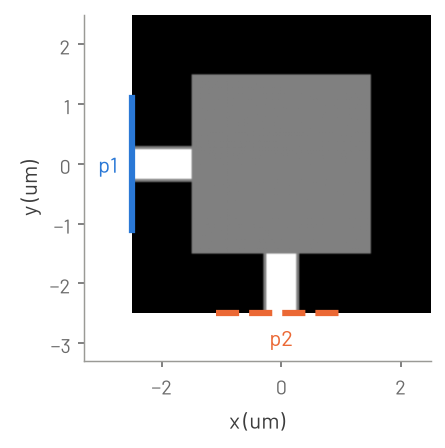

In [3]:
grid = design.LayerGrid(mesh, "design", pitch=0.05 * um)
HALF = 2.5 * um  # the box's half-width


def area_fraction(inside, x, y, pitch, samples=8):
    # Per pixel centred at (x[j], y[i]): the fraction of its area where inside(x, y).
    offsets = ((np.arange(samples) + 0.5) / samples - 0.5) * pitch
    xs = x[None, :, None, None] + offsets[None, None, None, :]
    ys = y[:, None, None, None] + offsets[None, None, :, None]
    return inside(xs, ys).mean(axis=(2, 3))


def in_arms(x, y):
    # The fixed guides: the input along x < -1.5 um, the output along y < -1.5 um.
    guide = WIDTH / 2
    return ((x < -1.5 * um) & (np.abs(y) <= guide)) | (
        (y < -1.5 * um) & (np.abs(x) <= guide)
    )


centres = -HALF + (np.arange(round(2 * HALF / grid.pitch)) + 0.5) * grid.pitch
corner_pixel = round((grid.origin[0] + HALF) / grid.pitch)  # same in x and y
inside_design = np.s_[
    corner_pixel : corner_pixel + grid.shape[0],
    corner_pixel : corner_pixel + grid.shape[1],
]
EXTENT = np.array([-HALF, HALF, -HALF, HALF]) / um


def window(density):
    # The whole 5 um x 5 um box as a pixel image: the guides around a design density.
    image = area_fraction(in_arms, centres, centres, grid.pitch)
    image[inside_design] = np.asarray(density)
    return image


start = np.full(grid.shape, 0.5)
nodes = np.asarray(mesh.nodes) / um
fig, ax = plt.subplots(figsize=(6, 3))
ax.imshow(window(start), origin="lower", extent=EXTENT, cmap="gray", vmin=0, vmax=1)
ports = (("p1", "port1", "C0", "-"), ("p2", "port2", "C1", "--"))  # solid, dashed
for port, face, colour, style in ports:
    xy = nodes[mesh.triangles[mesh.elements(face)]].reshape(-1, 3)[:, :2]
    lo, hi = xy.min(axis=0), xy.max(axis=0)
    ax.plot([lo[0], hi[0]], [lo[1], hi[1]], color=colour, ls=style, lw=3)
    # The label sits 0.4 um beyond the face's middle, outside the image.
    middle = (lo + hi) / 2
    ax.text(*middle * (1 + 0.4 / 2.5), port, color=colour, ha="center", va="center")
ax.set_xlim(EXTENT[0] - 0.8, EXTENT[1])  # room for the labels
ax.set_ylim(EXTENT[2] - 0.8, EXTENT[3])
ax.set_xlabel("x (um)")
ax.set_ylabel("y (um)");

In 3D, with [PyVista](https://docs.pyvista.org), seen from the ports' side: the
design square (tan, with its mesh) between the two guides (tan), the cladding
see-through, and the two port faces (red). The slab is to scale, 0.1 µm thick; the
plates are its top and bottom faces.

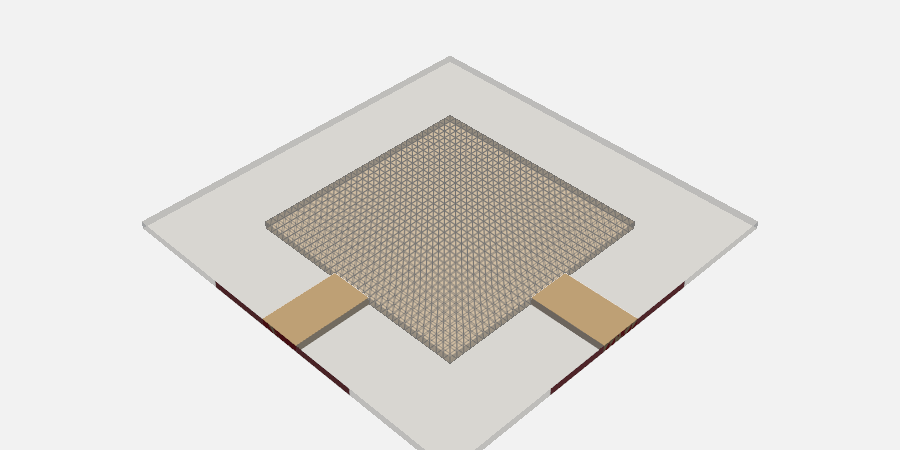

In [4]:
import pyvista as pv

pv.set_jupyter_backend("static")

volumes = pv.from_meshio(mesh.to_meshio())  # tetrahedra first, then triangles
volumes.points /= um
VIEW = (-1, -1, 1.2)  # the camera's direction: above the slab, on the ports' side


def part(region):
    """A region of the mesh as a PyVista grid, in um."""
    cells = mesh.elements(region)
    if region in mesh.surfaces:
        cells = cells + len(mesh.tetrahedra)
    return volumes.extract_cells(cells)


view = pv.Plotter(window_size=(900, 450))
view.add_mesh(part("cladding"), color="lightgrey", opacity=0.3)
view.add_mesh(part("core"), color="tan")
view.add_mesh(part("design"), color="tan", opacity=0.4, show_edges=True)
for face in ("port1", "port2"):
    view.add_mesh(part(face), color="#b5262f")
view.view_vector(VIEW, viewup=(0, 0, 1))
view.camera.zoom(1.4)
view.show()

Two hand-drawn bends set the scale before any optimization. The **arc design** is a
quarter ring 0.55 µm wide, of radius 1.5 µm about the corner (-1.5, -1.5) µm, that
joins the two guides; the **corner design** extends both guides until they meet in a
sharp L. Their pixels hold the area fraction of core (8 × 8 samples per pixel).

One driven problem at 1.55 µm with `excite=None` excites each port in turn and gives
the full 2 × 2 S-matrix. The media are lossless, so the remainder
1 - |S11|² - |S21|² is the power that leaves port 1's mode for neither port's
fundamental mode: radiated through the absorbing boundary, or carried out in the
guide's second (odd) mode, which the 0.55 µm guide supports at 1.55 µm as well. A direct solver suits these
repeated solves; `retain_memory` caps the factorizations kept for gradients at
512 MiB.

In [5]:
problem = gfem.Driven(frequency=F0, excite=None)
options = gfem.SolverOptions(linear_solver="direct", retain_memory=512 * 2**20)


def material(density, grid=grid):
    # The design volume's permittivity: 0 cladding, 1 core, per pixel of the grid.
    return gfem.MaterialField.interpolate(grid.to_elements(density), CLADDING, CORE)


def s_matrix(density):
    return gfem.solve(
        bend.with_material("design", material(density)), problem, options=options
    ).s


def transmission(s):
    # |S21|^2 at the first frequency: the power out of p2 in its fundamental mode.
    return abs(complex(s["p2", "p1"][0])) ** 2


def report(name, s):
    sent, back = transmission(s), abs(complex(s["p1", "p1"][0])) ** 2
    print(
        f"{name}: |S21|^2 = {sent:.4f}, |S11|^2 = {back:.1e}, "
        f"remainder = {1 - sent - back:.4f}"
    )
    return sent


def in_ring(x, y):
    r = np.hypot(x + 1.5 * um, y + 1.5 * um)
    return (np.abs(r - 1.5 * um) <= WIDTH / 2) & (x > -1.5 * um) & (y > -1.5 * um)


def in_corner(x, y):
    guide = WIDTH / 2
    return ((np.abs(y) <= guide) & (x <= guide)) | ((np.abs(x) <= guide) & (y <= guide))


arc = area_fraction(in_ring, grid.x, grid.y, grid.pitch)
corner = area_fraction(in_corner, grid.x, grid.y, grid.pitch)
arc_result = gfem.solve(  # the arc keeps its fields, for a field map
    bend.with_material("design", material(arc)),
    gfem.Driven(frequency=F0, excite=None, keep_fields=F0),
    options=options,
)
t_arc = report("arc design", arc_result.s)
t_corner = report("corner design", s_matrix(corner))

arc design: |S21|^2 = 0.6754, |S11|^2 = 3.0e-04, remainder = 0.3243


corner design: |S21|^2 = 0.0004, |S11|^2 = 3.9e-02, remainder = 0.9609


## From pixels to a material

The optimizer works on design parameters ρ, one per pixel in [0, 1], not on the
density the solve sees. `physical` maps one to the other in three steps on the grid:

1. **Mirror** about y = x: `0.5 * (rho + rho.T)`. Row i of the grid is at y[i] and
   column j at x[j], and the grid is square, so the transpose is the mirror
   (x, y) → (y, x). It swaps the two guides, and p1 with p2; the mesh has the same
   symmetry, so the design keeps it and S11 = S22. BEAMZ imposes the same mirror.
2. **Helmholtz filter** of radius 0.3 µm, BEAMZ's conic filter radius. `radius` is
   the cone-equivalent radius: the filter solves -r²∇²ρ̃ + ρ̃ = ρ with
   r = radius / 2√3 = 0.087 µm, about 1.7 pixels. At a 0.1 µm pitch, r would be
   smaller than one pixel and the filter would barely act; hence the 0.05 µm pitch.
   The pixel count does not enter the solve.
3. **Projection** towards 0 or 1 at threshold 0.5, with a sharpness β that the
   optimization raises step by step.

Each mesh element takes the bilinear interpolation of the pixels at its centroid.
At 0.05 µm pixels on cells of at most 0.1 µm, every pixel is sampled by some
centroid, so the grid raises no warning. Every density below, the snapshots and the final design,
comes from `physical`.

In [6]:
blur = design.helmholtz_filter(grid, radius=0.3 * um)


def physical(rho, beta):
    # Design parameters -> physical density: mirror about y = x, filter, project.
    return design.project(blur(0.5 * (rho + rho.T)), beta)


grid

LayerGrid('design', pitch=5e-08 m, shape=(60, 60), 6144 elements)

## The objective

For one design we solve the driven problem at 1.55 µm and read S21. The objective is
the power that misses the output guide's fundamental mode, 1 - |S21|². The media are
reciprocal, so S12 = S21 and |S21|² is the same in both directions: one number
stands for BEAMZ's forward and backward runs.

BEAMZ adds a penalty that pulls the core fraction towards 30 %, to avoid multimode
regions. This objective counts only the power in the output guide's fundamental
mode, so power lost to the guide's second (odd) mode already counts against it, and it
has no penalty. `has_aux` returns |S21|² and the core fraction with the gradient, and the
loop records both.

In [7]:
def loss(rho, beta):
    density = physical(rho, beta)
    t = jnp.abs(s_matrix(density)["p2", "p1"][0]) ** 2
    return 1 - t, (t, jnp.mean(density))  # missed power; aux: |S21|^2, core fraction


value_and_grad = jax.jit(jax.value_and_grad(loss, has_aux=True))

## Optimize

Adam on the raw pixels with step 0.1, clipped to [0, 1], from a uniform 0.5. The
start needs no noise: the gradient there is non-zero, and the mirror keeps it
symmetric. The projection sharpness β doubles from 1 to 32 every 7 steps
(continuation), 42 iterations in all, each one driven solve and its gradient. The
loop keeps four snapshots of the physical density, at iterations 0, 14, 27 and 41.

In [8]:
BETAS, STEPS_PER_BETA = (1.0, 2.0, 4.0, 8.0, 16.0, 32.0), 7
n_steps = len(BETAS) * STEPS_PER_BETA
snapshot_at = [round(i * (n_steps - 1) / 3) for i in range(4)]  # 0, 14, 27, 41
rho = jnp.full(grid.shape, 0.5)
optimizer = optax.adam(0.1)
state = optimizer.init(rho)
history, snapshots = [], {}
tic = time.perf_counter()
for beta in BETAS:
    for _ in range(STEPS_PER_BETA):
        (_, (t_last, fraction_last)), g = value_and_grad(rho, beta)
        if len(history) in snapshot_at:
            snapshots[len(history)] = np.asarray(physical(rho, beta))
        updates, state = optimizer.update(g, state)
        rho = jnp.clip(optax.apply_updates(rho, updates), 0.0, 1.0)
        t_last, fraction_last = float(t_last), float(fraction_last)
        history.append((t_last, fraction_last))
    print(
        f"beta = {beta:4.0f}: |S21|^2 = {t_last:.4f}, "
        f"core fraction = {fraction_last:.3f}"
    )
print(f"{n_steps} iterations in {time.perf_counter() - tic:.0f} s")

beta =    1: |S21|^2 = 0.7082, core fraction = 0.519


beta =    2: |S21|^2 = 0.8353, core fraction = 0.486


beta =    4: |S21|^2 = 0.9196, core fraction = 0.467


beta =    8: |S21|^2 = 0.9612, core fraction = 0.462


beta =   16: |S21|^2 = 0.9719, core fraction = 0.460


beta =   32: |S21|^2 = 0.9756, core fraction = 0.457
42 iterations in 95 s


|S21|² and the core fraction per iteration. The dotted black line is the arc
design's |S21|²; the thin grey lines mark where β doubles.

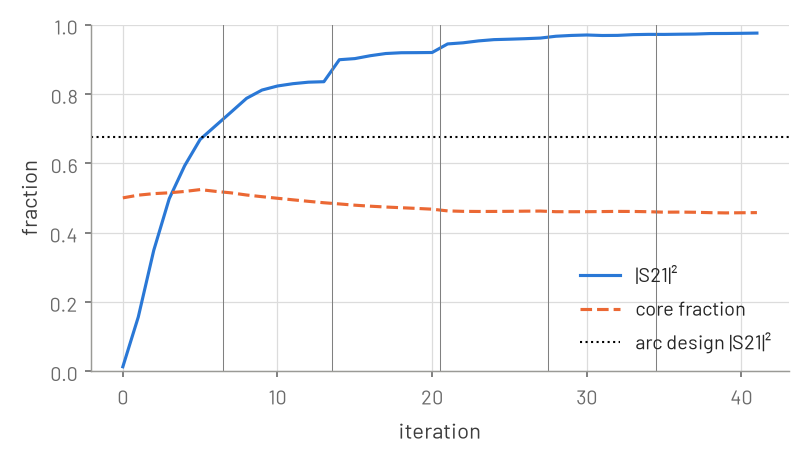

In [9]:
t_history, core_history = np.array(history).T
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(t_history, label="|S21|²")
ax.plot(core_history, label="core fraction")
ax.axhline(t_arc, color="k", ls=":", lw=1, label="arc design |S21|²")
for k in range(STEPS_PER_BETA, n_steps, STEPS_PER_BETA):
    ax.axvline(k - 0.5, color="gray", lw=0.5)
ax.set_ylim(0, 1)
ax.set_xlabel("iteration")
ax.set_ylabel("fraction")
ax.legend(loc="lower right");

## The design

The physical density at the four snapshots, white core and black cladding. The
design grows from the uniform start into curved strips of core about the inner
corner; by iteration 41 (β = 32) it is nearly binary.

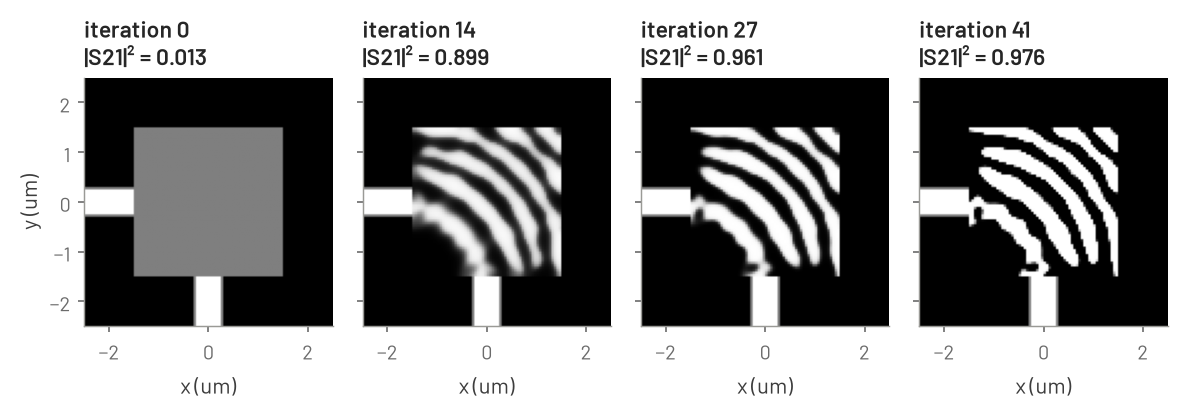

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(8, 2.6), sharey=True)
for ax, k in zip(axes, snapshot_at, strict=True):
    ax.imshow(
        window(snapshots[k]), origin="lower", extent=EXTENT, cmap="gray", vmin=0, vmax=1
    )
    ax.set_title(f"iteration {k}\n|S21|² = {history[k][0]:.3f}")
    ax.set_xlabel("x (um)")
axes[0].set_ylabel("y (um)")
fig.tight_layout();

The design we evaluate is `final`: the last physical density thresholded at 0.5, a
two-material image. Every number after this comes from it. Below, |S21|² of
iteration 41 next to that of `final`, and the share of pixels the last density
already had within 0.05 of 0 or 1. The element permittivities of `final` stay
fractional along material edges, since each element samples the pixels bilinearly.

In [11]:
last = physical(rho, BETAS[-1])
final = (last > 0.5).astype(float)
s_final = s_matrix(final)
t_final = transmission(s_final)
binary = float(jnp.mean((last < 0.05) | (last > 0.95)))
core = float(final.mean())
print(
    f"iteration {n_steps - 1}: |S21|^2 = {history[-1][0]:.4f} at beta = {BETAS[-1]:.0f}"
)
print(f"final: |S21|^2 = {t_final:.4f}, thresholded at 0.5, {core:.1%} core")
print(f"{100 * binary:.1f} % of the pixels lie within 0.05 of 0 or 1")

iteration 41: |S21|^2 = 0.9756 at beta = 32
final: |S21|^2 = 0.9746, thresholded at 0.5, 45.4% core
93.7 % of the pixels lie within 0.05 of 0 or 1


`final` in 3D, from the same side: its core pixels as blocks the slab's thickness
(tan), between the guides, inside the design square (black), with the cladding
see-through.

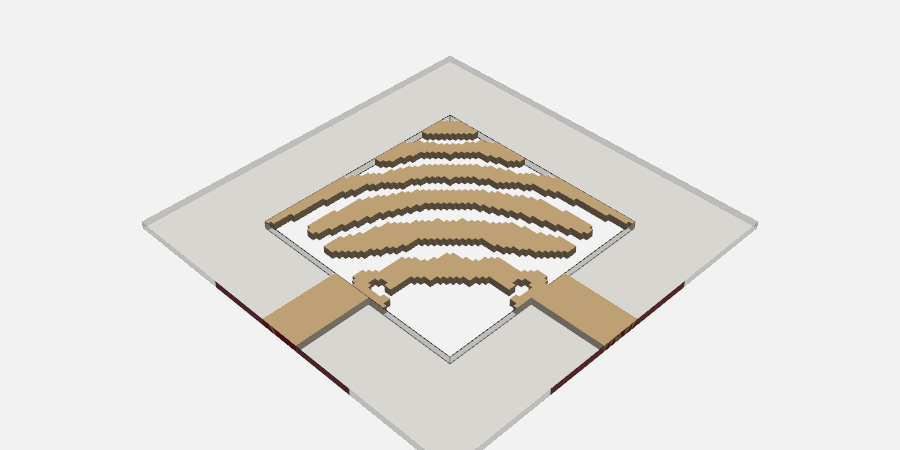

In [12]:
def core_pixels(density):
    # The design pixels past 0.5 as blocks through the slab, in um.
    blocks = pv.ImageData(
        dimensions=(grid.shape[1] + 1, grid.shape[0] + 1, 2),
        spacing=(grid.pitch / um, grid.pitch / um, nodes[:, 2].max()),
        origin=(grid.origin[0] / um, grid.origin[1] / um, 0),
    )
    blocks.cell_data["density"] = np.ravel(density)  # x fastest: rows are y
    return blocks.threshold(0.5, scalars="density")


view = pv.Plotter(window_size=(900, 450))
view.add_mesh(part("cladding"), color="lightgrey", opacity=0.3)
view.add_mesh(part("core"), color="tan")
view.add_mesh(core_pixels(final), color="tan")
view.add_mesh(part("design").extract_feature_edges(), color="black")
for face in ("port1", "port2"):
    view.add_mesh(part(face), color="#b5262f")
view.view_vector(VIEW, viewup=(0, 0, 1))
view.camera.zoom(1.4)
view.show()

## Trust: power balance and reciprocity

From here on every number is about `final`, except the eroded and dilated
variants in the mesh and box checks below, which perturb the filtered design that
`final` thresholds. One driven problem at 1.55 µm with both
ports excited gives its full S-matrix, and keeps both fields for the maps below.
Three properties of the model must show in it:

- **Power balance.** The media are lossless and the model is passive, so
  |S11|² + |S21|² ≤ 1. The remainder 1 - |S11|² - |S21|² is power radiated through
  the absorbing boundary or carried out in the guide's second (odd) mode; one
  fundamental-mode port per guide does not tell the two apart.
- **Reciprocity.** The media are reciprocal, so S12 = S21: |S21|² is BEAMZ's forward
  and backward transmission at once.
- **Symmetry.** The design and the mesh are mirror images about y = x, so
  |S11|² = |S22|².

The same wave ports on a straight open guide transmit |S21|² > 0.999 in gfem's test
suite (`tests/unit/test_driven_wave_ports.py`).

In [13]:
trust = gfem.solve(
    bend.with_material("design", material(final)),
    gfem.Driven(frequency=F0, excite=None, keep_fields=F0),
    options=options,
)


def powers(s):
    # Per frequency: |S21|^2, |S11|^2, |S22|^2 and |S12 - S21|.
    s21, s12 = np.asarray(s["p2", "p1"]), np.asarray(s["p1", "p2"])
    s11, s22 = np.asarray(s["p1", "p1"]), np.asarray(s["p2", "p2"])
    return np.abs(s21) ** 2, np.abs(s11) ** 2, np.abs(s22) ** 2, np.abs(s12 - s21)


t_trust, r11, r22, recip = (float(v[0]) for v in powers(trust.s))
print(f"final at F0: |S21|^2 = {t_trust:.4f}, |S11|^2 = {r11:.1e}, |S22|^2 = {r22:.1e}")
print(f"reciprocity: |S12 - S21| = {recip:.1e}")
print(f"power balance: |S11|^2 + |S21|^2 = {r11 + t_trust:.6f}, at most 1")
print(
    "remainder, radiated or carried out in the second (odd) mode: "
    f"{1 - r11 - t_trust:.4f}"
)

final at F0: |S21|^2 = 0.9746, |S11|^2 = 5.3e-05, |S22|^2 = 5.3e-05
reciprocity: |S12 - S21| = 1.8e-15
power balance: |S11|^2 + |S21|^2 = 0.974660, at most 1
remainder, radiated or carried out in the second (odd) mode: 0.0253


## Trust: the spectrum

The objective sees one wavelength. A uniform sweep of 13 wavelengths, 1.2 to 1.8 µm
in 0.05 µm steps with 1.55 µm among them, shows what the design does around it. Both
ports are excited at every wavelength, so the checks above repeat across the band.
Each wavelength costs its own factorization; the port modes come from one sweep
over the band.

In [14]:
wavelengths = np.linspace(1.2, 1.8, 13) * um
spectrum = gfem.solve(
    bend.with_material("design", material(final)),
    gfem.Driven(frequency=c / wavelengths, excite=None),
    options=options,
)
t_band, r11_band, r22_band, recip_band = powers(spectrum.s)
remainder = 1 - r11_band - t_band
in_um = np.round(wavelengths / um, 2)
claimed = in_um >= 1.3  # BEAMZ's band, 1.3-1.8 um
low, high = np.argmin(np.where(claimed, t_band, 2)), np.argmax(t_band * claimed)
print(f"band: max |S12 - S21| = {recip_band.max():.1e}")
print(f"band: max |S11|^2 + |S21|^2 = {(r11_band + t_band).max():.4f}")
print(f"band: max |S11|^2 = {r11_band.max():.1e}, max |S22|^2 = {r22_band.max():.1e}")
print(
    f"|S21|^2 over 1.3-1.8 um: min {t_band[low]:.4f} at {in_um[low]} um, "
    f"max {t_band[high]:.4f} at {in_um[high]} um"
)
print("wavelength (um)  |S21|^2  |S11|^2  remainder")
for lam, sent, back, rest in zip(in_um, t_band, r11_band, remainder, strict=True):
    print(f"{lam:15.2f}  {sent:7.4f}  {back:7.1e}  {rest:9.4f}")

band: max |S12 - S21| = 4.5e-14
band: max |S11|^2 + |S21|^2 = 0.9747
band: max |S11|^2 = 6.3e-02, max |S22|^2 = 6.3e-02
|S21|^2 over 1.3-1.8 um: min 0.6049 at 1.8 um, max 0.9746 at 1.55 um
wavelength (um)  |S21|^2  |S11|^2  remainder
           1.20   0.5103  6.3e-02     0.4265
           1.25   0.5895  2.3e-02     0.3879
           1.30   0.6389  3.0e-03     0.3581
           1.35   0.6674  1.9e-03     0.3307
           1.40   0.7931  5.4e-03     0.2015
           1.45   0.8977  3.4e-03     0.0989
           1.50   0.9638  2.7e-05     0.0362
           1.55   0.9746  5.3e-05     0.0253
           1.60   0.9440  1.7e-04     0.0558
           1.65   0.8980  7.2e-04     0.1013
           1.70   0.8415  8.7e-04     0.1576
           1.75   0.7421  3.0e-03     0.2549
           1.80   0.6049  8.2e-03     0.3869


|S21|² (solid) and the remainder (dashed) against wavelength; the dotted line marks
1.55 µm. |S11|² is in the table above, not plotted: away from 1.55 µm, most of what
|S21|² loses goes into the remainder.

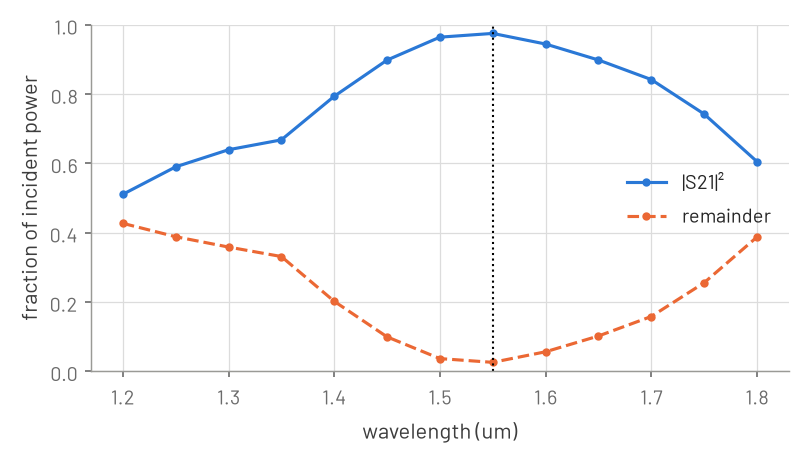

In [15]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(wavelengths / um, t_band, marker="o", ms=3, label="|S21|²")
ax.plot(wavelengths / um, remainder, ls="--", marker="o", ms=3, label="remainder")
ax.axvline(WAVELENGTH / um, color="k", ls=":", lw=1)
ax.set_ylim(0, 1)
ax.set_xlabel("wavelength (um)")
ax.set_ylabel("fraction of incident power")
ax.legend(loc="center right");

## The fields

|E_z| in the mid-plane of the slab with 1 W incident in the fundamental mode at p1,
for the arc design and for `final`, on one grey scale. Of the arc and corner
designs, the arc is the one that guides, so it is the one shown. Each map samples
the kept field at 200 × 200 points with `Field.at`, and the blue line is the core
edge (ρ = 0.5).

This is the frequency-domain amplitude at 1.55 µm, not BEAMZ's time-integrated
energy flow. An amplitude is the square root of a power, so the arc design's
radiation, a third of the input spread thinly over the box, still shows as lobes
leaving the bend. The power flow enters below as a number only.

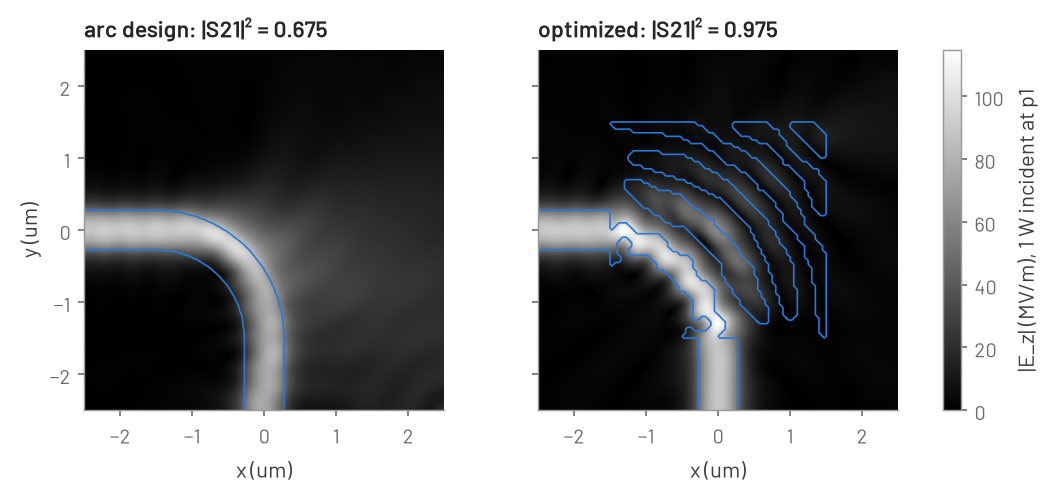

In [16]:
step = 2 * HALF / 200
along = -HALF + (np.arange(200) + 0.5) * step
X, Y = np.meshgrid(along, along)
thickness = np.ptp(nodes[:, 2]) * um
plane = np.stack([X.ravel(), Y.ravel(), np.full(X.size, thickness / 2)], axis=1)


def ez_map(result):
    # |E_z| in MV/m at the mid-plane, port p1 fed.
    e = np.asarray(result.e_field(F0, excite="p1").at(plane))
    return np.abs(e[:, 2]).reshape(X.shape) / 1e6


maps = {
    f"arc design: |S21|² = {t_arc:.3f}": (arc, ez_map(arc_result)),
    f"optimized: |S21|² = {t_trust:.3f}": (final, ez_map(trust)),
}
vmax = max(ez.max() for _, ez in maps.values())
fig, axes = plt.subplots(1, 2, figsize=(7, 3.2), sharey=True, layout="constrained")
for ax, (title, (density, ez)) in zip(axes, maps.items(), strict=True):
    image = ax.imshow(ez, origin="lower", extent=EXTENT, cmap="gray", vmin=0, vmax=vmax)
    edge = contour_generator(centres / um, centres / um, window(density)).lines(0.5)
    for line in edge:
        ax.plot(*line.T, color="C0", ls="-", lw=0.8)
    ax.set_title(title)
    ax.set_xlabel("x (um)")
    ax.grid(False)
axes[0].set_ylabel("y (um)")
fig.colorbar(image, ax=axes, label="|E_z| (MV/m), 1 W incident at p1");

The same two solves in 3D: E_z at t = 0, Re(E_z), on the mid-plane of the slab,
with 1 W incident at p1, on one colour scale; the black line is the core edge
(ρ = 0.5), as above. Where the amplitude maps show how strong the field is, the
phase fronts show where it goes: in the arc design they curve out of the ring
into the cladding; in `final` they turn with the core.

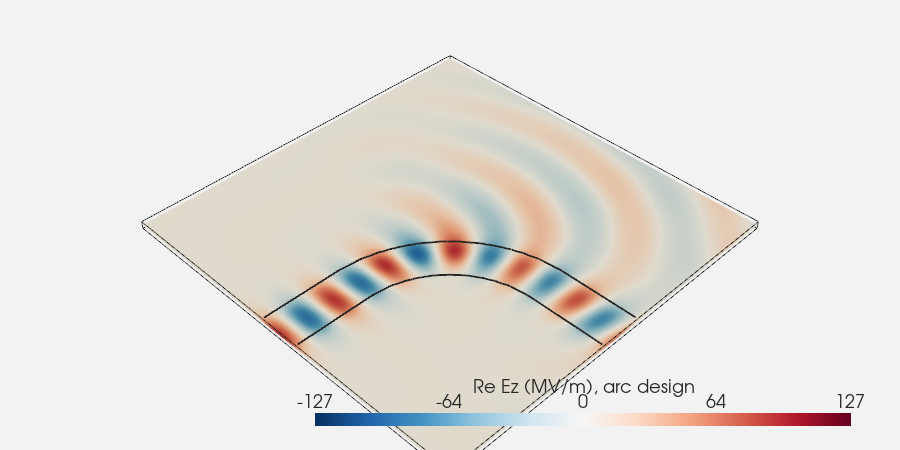

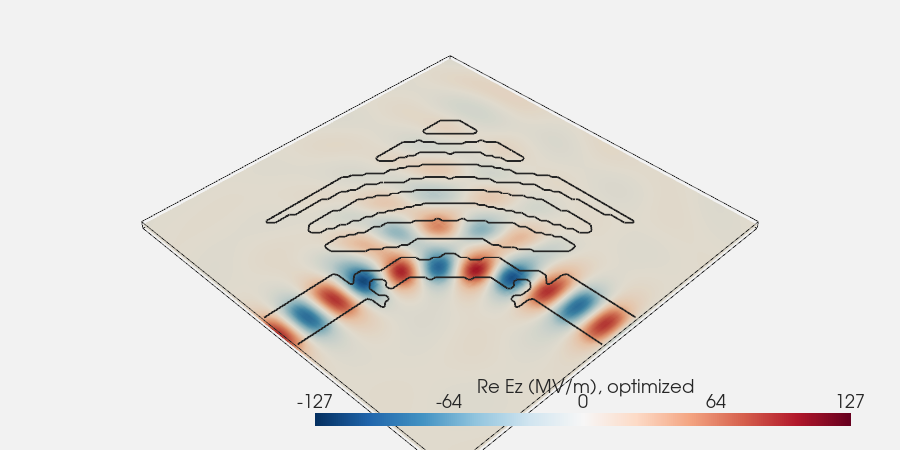

In [17]:
def core_edge(density, z):
    # The core edge (rho = 0.5) of the pixel image as lines at height z, in um.
    lines = contour_generator(centres / um, centres / um, window(density)).lines(0.5)
    return pv.merge(
        [pv.lines_from_points(np.c_[line, np.full(len(line), z)]) for line in lines]
    )


scenes = {"arc design": (arc, arc_result), "optimized": (final, trust)}
sampled = {}
for name, (_, result) in scenes.items():
    sampled[name] = result.e_field(F0, excite="p1").to_pyvista()
    sampled[name].points /= um
    sampled[name]["Re Ez"] = sampled[name]["E_real"][:, 2] / 1e6  # MV/m
peak = max(np.abs(field["Re Ez"]).max() for field in sampled.values())

for name, (density, _) in scenes.items():
    view = pv.Plotter(window_size=(900, 450))
    view.add_mesh(
        sampled[name].slice(normal="z"),
        scalars="Re Ez",
        cmap="RdBu_r",
        clim=(-peak, peak),
        scalar_bar_args={"title": f"Re Ez (MV/m), {name}", "fmt": "%.0f"},
    )
    view.add_mesh(core_edge(density, thickness / um), color="black", line_width=2)
    view.add_mesh(sampled[name].outline(), color="black")
    view.view_vector(VIEW, viewup=(0, 0, 1))
    view.camera.zoom(1.4)
    view.show()

## Trust: the mesh and the box

Three checks bound what the design's and the model's choices cost: an etch, the box
and the element order.

- **Eroded and dilated.** The filter gives the design a length scale, not a minimum
  feature size. `design.robust` projects the filtered last iterate at thresholds
  0.6, 0.5 and 0.4 (β = 64, δ = 0.1). This is the filtered design whose 0.5
  threshold is `final`: the robust nominal, at 0.5, is its β = 64 projection, and
  the eroded and dilated variants thin or widen every core strip, as an over- or
  under-etch would. All three are projected densities, not thresholded ones, so
  their |S21|² is read against the robust nominal's.
- **The box.** `data/bend_7um.msh` is the same mesh grown to 7 µm × 7 µm, the port
  faces on x = -3.5 µm and y = -3.5 µm. Inside the 5 µm box it is identical node for
  node, so the same layer grid and pixels apply, and the absorbing boundary sits
  2 µm from the design instead of 1 µm. The guides are lossless, so the longer feeds
  do not change |S21|². It prints the change ΔT of |S21|² against `final`'s.
- **The order.** Third-order elements on the same mesh bound the field
  discretization error at a fixed material sampling, again as ΔT against `final`.
  This is the largest solve here, so it comes last; it keeps both fields for the
  comparison below.

In [18]:
variants = design.robust(blur(0.5 * (rho + rho.T)), beta=64.0, delta=0.1)
t_eroded = report("eroded", s_matrix(variants.eroded))
t_robust = report("robust nominal", s_matrix(variants.nominal))
t_dilated = report("dilated", s_matrix(variants.dilated))
print(f"final (its 0.5 threshold): |S21|^2 = {t_final:.4f}")

eroded: |S21|^2 = 0.8587, |S11|^2 = 6.6e-02, remainder = 0.0750


robust nominal: |S21|^2 = 0.9763, |S11|^2 = 4.8e-05, remainder = 0.0237


dilated: |S21|^2 = 0.9148, |S11|^2 = 5.7e-05, remainder = 0.0852
final (its 0.5 threshold): |S21|^2 = 0.9746


In [19]:
mesh_7um = gfem.Mesh.from_gmsh(Path("data/bend_7um.msh"), length_unit="um")
bend_7um = gfem.Model(
    mesh_7um, materials=bend.materials, boundaries=bend.boundaries, ports=bend.ports
)
grid_7um = design.LayerGrid(mesh_7um, "design", pitch=grid.pitch)
print(
    f"layer grid: {grid_7um.shape} pixels from {np.asarray(grid_7um.origin) / um} um, "
    f"against {grid.shape} from {np.asarray(grid.origin) / um} um"
)
s_7um = gfem.solve(
    bend_7um.with_material("design", material(final, grid=grid_7um)),
    problem,
    options=options,
).s
t_7um = transmission(s_7um)
print(f"7 x 7 um box: |S21|^2 = {t_7um:.4f}, delta T = {t_7um - t_final:+.1e}")

layer grid: (60, 60) pixels from [-1.5 -1.5] um, against (60, 60) from [-1.5 -1.5] um


7 x 7 um box: |S21|^2 = 0.9744, delta T = -2.3e-04


In [20]:
order3 = gfem.solve(
    bend.with_material("design", material(final)),
    gfem.Driven(frequency=F0, excite=None, keep_fields=F0),
    options=gfem.SolverOptions(
        linear_solver="direct", order=3, retain_memory=512 * 2**20
    ),
)
t_order3 = transmission(order3.s)
print(f"order 3: |S21|^2 = {t_order3:.4f}, delta T = {t_order3 - t_final:+.1e}")

order 3: |S21|^2 = 0.9746, delta T = +5.7e-06


## Comparing with BEAMZ

BEAMZ reports 92.7 % for its design
([the BEAMZ example](https://www.beamz.tech/examples/ceviche_bend)): the mean of the
forward and backward transmission, each the time-integrated Poynting flux through a
2.2 µm monitor across the output guide divided by the flux through one across the
input guide. That ratio counts everything that crosses the output window (the
fundamental mode, the guide's second (odd) mode, and radiation that passes
through the window)
relative to the net input. |S21|² counts only the fundamental mode per incident
watt, so it is the stricter of the two. BEAMZ reports above 95 % (its flux ratio)
over 1.3-1.8 µm, from 12 single-wavelength runs; over the same band, `final` has
|S21|² from 0.605 to 0.975 (the spectrum above).

The flux ratio can be estimated from the order-3 fields. `window_flux` integrates
the time-averaged Poynting vector ½Re(E × H*) across a 2.2 µm window (|s| ≤ 1.1 µm)
in each guide, with H = B / μ₀ from `Field.b()`, and multiplies by the slab
thickness. BEAMZ's monitors sit 2 µm from the bend's centre, on x = -2 µm and
y = -2 µm here; those are node lines of the mesh, where the sampled B jumps, so the
windows sit at -1.95 µm, the centres of the next cells. B is one order lower than
E, hence the order-3 fields. The check on the estimate is the input flux against
1 - |S11|², the net power the port delivers.

In [21]:
across = np.linspace(-1.1, 1.1, 881) * um  # the 2.2 um window


def window_flux(e):
    # Time-averaged power (W) through the window across each guide at -1.95 um,
    # counted towards the design square: (input guide along x, output along y).
    b = e.b()
    flux = []
    for axis in (0, 1):
        points = np.zeros((across.size, 3))
        points[:, axis] = -1.95 * um
        points[:, 1 - axis] = across
        points[:, 2] = thickness / 2
        poynting = 0.5 * np.real(
            np.cross(np.asarray(e.at(points)), np.conj(np.asarray(b.at(points)) / mu_0))
        )
        flux.append(np.trapezoid(poynting[:, axis], across) * thickness)
    return flux


ratios = []
for port, into, out_of in (("p1", 0, 1), ("p2", 1, 0)):
    flux = window_flux(order3.e_field(F0, excite=port))
    delivered = 1 - abs(complex(order3.s[port, port][0])) ** 2
    ratios.append(-flux[out_of] / flux[into])
    sii = f"|S{port[1]}{port[1]}|^2"  # the fed port's reflection, S11 or S22
    print(
        f"{port} fed: P_in = {flux[into]:.4f} W, "
        f"1 - {sii} = {delivered:.4f}, P_out / P_in = {ratios[-1]:.4f}"
    )
    print(f"  P_in short of 1 - {sii} by {delivered - flux[into]:.1e} W")
print(
    f"BEAMZ-style flux ratio: {ratios[0]:.4f} (p1 -> p2), {ratios[1]:.4f} "
    f"(p2 -> p1), mean {np.mean(ratios):.4f}; |S21|^2 = {t_order3:.4f} at order 3"
)
print(f"flux ratio - |S21|^2 = {np.mean(ratios) - t_order3:+.1e}")

p1 fed: P_in = 0.9985 W, 1 - |S11|^2 = 1.0000, P_out / P_in = 0.9773
  P_in short of 1 - |S11|^2 by 1.5e-03 W


p2 fed: P_in = 0.9988 W, 1 - |S22|^2 = 1.0000, P_out / P_in = 0.9767
  P_in short of 1 - |S22|^2 by 1.2e-03 W
BEAMZ-style flux ratio: 0.9773 (p1 -> p2), 0.9767 (p2 -> p1), mean 0.9770; |S21|^2 = 0.9746 at order 3
flux ratio - |S21|^2 = +2.4e-03


On BEAMZ's definition, `final` has a flux ratio of 0.977, against |S21|² = 0.975
at order 3: they differ by 2.4 × 10⁻³. The estimate's own error is of that order:
the input flux falls short of the net power the port delivers, 1 - |S11|² (or
1 - |S22|²), by 1.5 × 10⁻³ W with p1 fed and 1.2 × 10⁻³ W with p2 fed. At this accuracy the
estimate does not tell what the difference is made of.

The two designs come from different solvers (FDTD against the finite-element
method), boundaries (a sponge PML against an absorbing boundary), objectives and
optimizer settings. Equal or different numbers compare two designs under one
definition, not two solvers.

## Limits

- **The 2D slab model.** A top view in effective indices, posed as a slab one
  element thick between PEC plates. No vertical stack, substrate leakage or
  out-of-plane loss enters; 2.25 and 1.444 are taken as given, as BEAMZ takes them.
- **An absorbing boundary, not a PML.** A second-order absorbing boundary 1 µm from
  the design. The 7 µm × 7 µm re-solve moves |S21|² by -2.3 × 10⁻⁴: a bound for
  this design, not a guarantee for others.
- **The mesh is part of the material model.** Each element takes the pixel image at
  its centroid, so a finer mesh changes the permittivity as well as the field. The
  order-3 re-solve (ΔT = +5.7 × 10⁻⁶) bounds only the field error at a fixed
  sampling, and only at 1.55 µm; towards 1.2 µm the mesh has fewer cells per guided
  wavelength. Re-check a design on a finer mesh before trusting the third digit.
- **The remainder is not split.** 1 - |S11|² - |S21|² (0.025 at 1.55 µm) lumps
  radiation and the guide's second (odd) mode, which the 0.55 µm guide supports at
  1.55 µm. Separating them needs a second port mode per port.
- **One wavelength.** The objective is |S21|² at 1.55 µm; the spectrum is
  evaluated, not optimized, and |S21|² falls to 0.605 at 1.8 µm. A broadband design
  would sum the objective over wavelengths, as the topology tutorial does over a
  pass and a stop frequency.
- **A length scale from the filter only.** The 0.3 µm filter radius gives the
  design a length scale but no guaranteed minimum width, of core strips or of the
  gaps between them. The eroded and dilated variants printed above transmit 0.859
  and 0.915, against 0.976 for the robust nominal. Optimizing the worst of the
  three, as the topology tutorial does, costs three solves per iteration.
- **Not a solver comparison with BEAMZ.** The shared flux ratio compares two
  designs under BEAMZ's definition, estimated from sampled fields and checked
  against 1 - |S11|². The solvers, boundaries, objectives and optimizer settings
  differ.

## Next

- `docs/recipes/robust-optimization.md`: eroded, nominal and dilated designs in
  the loop.
- `docs/recipes/s-parameter-gradient.md`: what is differentiable in a driven solve.
- `docs/recipes/measurements.md`: `Field.at` and `Field.b()`, the probes behind the
  field maps and the flux ratio.
- `gfem.design` reference: `LayerGrid`, `helmholtz_filter`, `project`, `robust`.